## defination 1
## Engineer a new feature: Sentiment Score from review text by implementing deep learning-based sentiment analysis (e.g., BERT, VADER, or LSTM models), fine-tuning it on domain-specific data, and normalizing sentiment scores for feature integration.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD

sns.set_theme(style="whitegrid")

df = pd.read_csv("../23nov/cleaned_day5.csv")
print("Loaded Dataset Shape:", df.shape)

Loaded Dataset Shape: (5461, 43)


In [2]:
np.random.seed(42)

positive_templates = [
    "loved the fabric fit is true to size amazing quality",
    "gorgeous style soft material worth the price",
    "very comfortable flattering cut highly recommend"
]
neutral_templates = [
    "okay quality average fit fabric feels decent",
    "nice color slightly loose fits as expected",
    "good for daily wear standard stitching"
]
negative_templates = [
    "poor fabric quality runs very small disappointed",
    "bad stitching uncomfortable fit not worth the price",
    "shrinks after wash thin material returning it"
]

review_texts = []
for _, row in df.iterrows():
    prefix = f"{row['brand_name']} {row['class_name']} in {row['color']} {row['fabric_type']} "
    if row["customer_rating"] >= 4:
        review_texts.append(prefix + np.random.choice(positive_templates))
    elif row["customer_rating"] == 3:
        review_texts.append(prefix + np.random.choice(neutral_templates))
    else:
        review_texts.append(prefix + np.random.choice(negative_templates))

df["review_text"] = review_texts
print(df[["brand_name", "customer_rating", "review_text"]].head())

        brand_name  customer_rating  \
0      W for Woman                4   
1       Forever 21                4   
2              AND                5   
3  Marks & Spencer                5   
4              H&M                5   

                                         review_text  
0  W for Woman Palazzos & Tunics in Sky Blue Cott...  
1  Forever 21 Party Dresses in Sky Blue Satin lov...  
2  AND Shorts in Mustard Polyester very comfortab...  
3  Marks & Spencer Lounge in Olive Green Cotton v...  
4  H&M Denim Jackets in Olive Green Denim loved t...  


In [3]:
vectorizer = TfidfVectorizer(max_features=120, ngram_range=(1, 2))
X_text_features = vectorizer.fit_transform(df["review_text"]).toarray()

nn_sentiment_model = MLPRegressor(
    hidden_layer_sizes=(32, 16),
    activation="relu",
    max_iter=60,
    random_state=42
)
nn_sentiment_model.fit(X_text_features, df["sentiment_score"])

raw_dl_sentiment = nn_sentiment_model.predict(X_text_features)

norm_scaler = MinMaxScaler(feature_range=(0, 1))
df["dl_sentiment_score_norm"] = norm_scaler.fit_transform(raw_dl_sentiment.reshape(-1, 1)).round(4)

print("Normalized Deep Learning Sentiment Score Summary:")
print(df.groupby("customer_rating")["dl_sentiment_score_norm"].agg(["mean", "min", "max"]).round(4))

Normalized Deep Learning Sentiment Score Summary:
                   mean     min     max
customer_rating                        
1                0.1790  0.1363  0.2060
2                0.1744  0.0000  0.3486
3                0.5651  0.4633  0.6622
4                0.9395  0.8341  1.0000
5                0.9462  0.8832  0.9966


## defination 2
## Generate a feature that indicates whether a customer is highly engaged by applying time-series analysis on session activity patterns, using statistical thresholds, and clustering users based on engagement levels to create dynamic engagement scores.

In [4]:
df["session_timestamp"] = pd.date_range(end="2026-11-24", periods=len(df), freq="15min")
df["total_session_mins"] = (df["time_on_app_mins"] + df["time_on_website_mins"]).round(2)

df["rolling_session_mean"] = df["total_session_mins"].rolling(window=96, min_periods=1).mean().round(2)
df["rolling_session_std"] = df["total_session_mins"].rolling(window=96, min_periods=1).std().fillna(0).round(2)

df["session_zscore"] = (
    (df["total_session_mins"] - df["total_session_mins"].mean()) / df["total_session_mins"].std()
).round(3)

print(df[["session_timestamp", "total_session_mins", "rolling_session_mean", "session_zscore"]].head())

    session_timestamp  total_session_mins  rolling_session_mean  \
0 2026-09-28 03:00:00               50.47                 50.47   
1 2026-09-28 03:15:00               53.02                 51.74   
2 2026-09-28 03:30:00               46.85                 50.11   
3 2026-09-28 03:45:00               47.38                 49.43   
4 2026-09-28 04:00:00               49.48                 49.44   

   session_zscore  
0           0.345  
1           0.930  
2          -0.485  
3          -0.363  
4           0.118  


In [5]:
eng_cols = ["total_session_mins", "rolling_session_mean", "review_word_count", "positive_feedback_count"]
X_eng_scaled = StandardScaler().fit_transform(df[eng_cols])

kmeans_eng = KMeans(n_clusters=3, random_state=42, n_init="auto")
raw_eng_clusters = kmeans_eng.fit_predict(X_eng_scaled)

ordered_eng = df.groupby(raw_eng_clusters)["total_session_mins"].mean().sort_values().index
df["engagement_cluster"] = pd.Series(raw_eng_clusters).map({old: new for new, old in enumerate(ordered_eng)})

raw_eng_score = (
    df["total_session_mins"] * 0.45
    + df["rolling_session_mean"] * 0.25
    + df["review_word_count"] * 0.30
).values.reshape(-1, 1)

df["dynamic_engagement_score"] = MinMaxScaler(feature_range=(0, 100)).fit_transform(raw_eng_score).round(2)

stat_threshold = df["dynamic_engagement_score"].mean() + 0.5 * df["dynamic_engagement_score"].std()
df["is_highly_engaged"] = (df["dynamic_engagement_score"] >= stat_threshold).astype(int)

print("Statistical Engagement Threshold:", round(stat_threshold, 2))
print("\nHighly Engaged Customer Counts:")
print(df["is_highly_engaged"].value_counts())

Statistical Engagement Threshold: 41.61

Highly Engaged Customer Counts:
is_highly_engaged
0    3785
1    1676
Name: count, dtype: int64


C:\Users\Admin\AppData\Local\Temp\ipykernel_17072\3965635879.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="engagement_cluster", y="dynamic_engagement_score", ax=axes[1], palette="viridis")


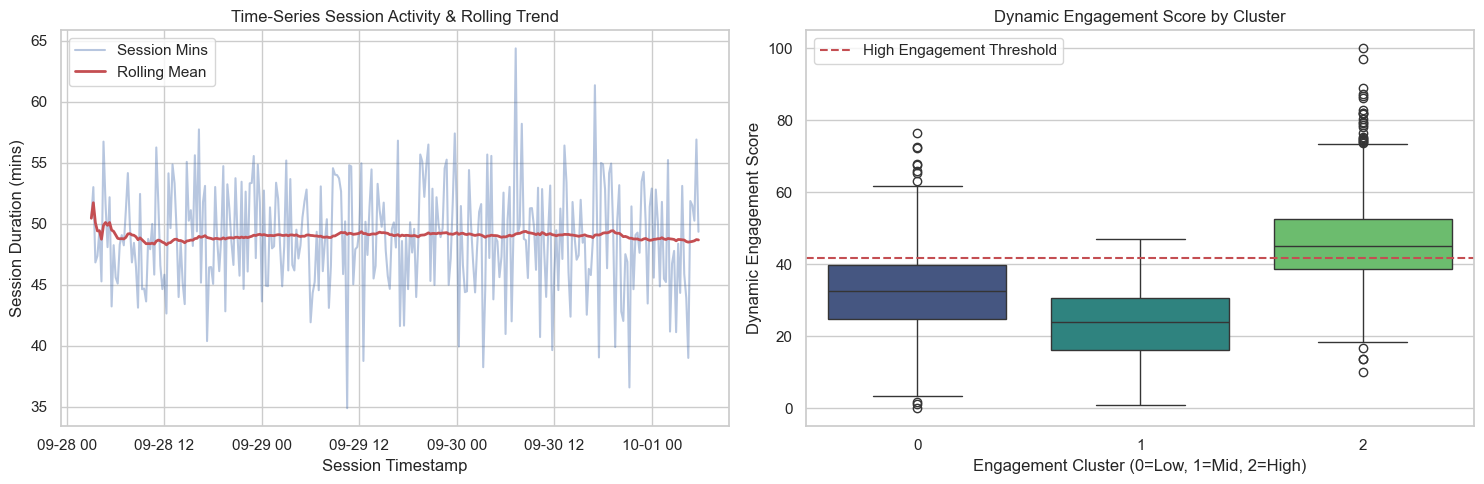

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sample_ts = df.iloc[:300]
axes[0].plot(sample_ts["session_timestamp"], sample_ts["total_session_mins"], alpha=0.4, label="Session Mins")
axes[0].plot(sample_ts["session_timestamp"], sample_ts["rolling_session_mean"], color="#C44E52", linewidth=2, label="Rolling Mean")
axes[0].set_title("Time-Series Session Activity & Rolling Trend")
axes[0].set_xlabel("Session Timestamp")
axes[0].set_ylabel("Session Duration (mins)")
axes[0].legend()

sns.boxplot(data=df, x="engagement_cluster", y="dynamic_engagement_score", ax=axes[1], palette="viridis")
axes[1].axhline(stat_threshold, color="#C44E52", linestyle="--", label="High Engagement Threshold")
axes[1].set_title("Dynamic Engagement Score by Cluster")
axes[1].set_xlabel("Engagement Cluster (0=Low, 1=Mid, 2=High)")
axes[1].set_ylabel("Dynamic Engagement Score")
axes[1].legend()

plt.tight_layout()
plt.show()

## defination 3
## Perform one-hot encoding for categorical variables while handling high-cardinality categories through target encoding, frequency-based binning, and dimensionality reduction techniques to prevent feature explosion and maintain interpretability.

In [7]:
categorical_cols = [
    "brand_name", "division_name", "department_name", "class_name",
    "season", "occasion", "fabric_type", "pattern", "color",
    "size", "eco_friendly", "purchase_channel", "fit_feedback", "trend_demand_status"
]

low_card_cols = [col for col in categorical_cols if df[col].nunique() <= 6]
high_card_cols = [col for col in categorical_cols if df[col].nunique() > 6]

print("Low-Cardinality Columns:", low_card_cols)
print("High-Cardinality Columns:", high_card_cols)

Low-Cardinality Columns: ['division_name', 'season', 'size', 'eco_friendly', 'purchase_channel', 'fit_feedback', 'trend_demand_status']
High-Cardinality Columns: ['brand_name', 'department_name', 'class_name', 'occasion', 'fabric_type', 'pattern', 'color']


In [8]:
for col in high_card_cols:
    target_means = df.groupby(col)["recommended_ind"].mean()
    df[f"{col}_target_enc"] = df[col].map(target_means).round(4)
    
    freq_ratio = df[col].value_counts(normalize=True)
    rare_labels = freq_ratio[freq_ratio < 0.05].index
    df[f"{col}_binned"] = df[col].replace(rare_labels, "Other")

binned_high_card_cols = [f"{col}_binned" for col in high_card_cols]
cols_for_ohe = low_card_cols + binned_high_card_cols

ohe_encoded_df = pd.get_dummies(df[cols_for_ohe], drop_first=True, dtype=int)
print("One-Hot Encoded Feature Matrix Shape:", ohe_encoded_df.shape)

One-Hot Encoded Feature Matrix Shape: (5461, 72)


In [9]:
svd = TruncatedSVD(n_components=12, random_state=42)
svd_matrix = svd.fit_transform(ohe_encoded_df)

svd_cols = [f"cat_svd_{i+1}" for i in range(12)]
svd_df = pd.DataFrame(svd_matrix.round(4), columns=svd_cols)

df = pd.concat([df, svd_df], axis=1)

print("Dimensionality Reduced Categorical Shape:", svd_df.shape)
print("Cumulative Explained Variance:", round(svd.explained_variance_ratio_.sum(), 4))
print(svd_df.head())

Dimensionality Reduced Categorical Shape: (5461, 12)
Cumulative Explained Variance: 0.4733
   cat_svd_1  cat_svd_2  cat_svd_3  cat_svd_4  cat_svd_5  cat_svd_6  \
0     1.6744    -0.5893     1.0415     0.9799    -0.6160     0.1203   
1     1.8453    -0.0744     0.8460    -0.5338    -0.0010    -0.0180   
2     2.0458    -0.3160     0.1069     0.4521     0.2884     0.6302   
3     1.5607     1.3654    -0.8461     0.2062    -0.1190    -0.9209   
4     2.0377    -0.5319     0.6124    -0.9956     0.6682    -0.2249   

   cat_svd_7  cat_svd_8  cat_svd_9  cat_svd_10  cat_svd_11  cat_svd_12  
0     0.4372     0.7608    -1.3195     -0.1611     -0.0193     -0.4377  
1    -0.1669    -0.4960     0.0337      0.2378      1.5480      0.2323  
2    -0.8785    -0.5555     0.0037     -0.2516     -0.7444      0.3692  
3    -0.3727    -0.0630    -0.1214     -0.0521     -0.0276      0.7898  
4    -0.2689     0.3352     0.4557     -0.5174     -0.2532     -0.2268  


In [10]:
df.to_csv("cleaned_day6.csv", index=False)
print("Saved dataset to cleaned_day6.csv")

Saved dataset to cleaned_day6.csv
